# Per-Camera Ticket Trends Based on Eric's Results

Yihan Hu · Descriptive ticket histories · Based on Eric's unchanged registry

## tl;dr

All **4,610** original enforcement groups are retained. The new snapshot contains **45,880,884 raw camera-ticket records**; **42,167,563 unique tickets** match these groups on or after their original inferred activation dates. **41,500 reconciliation checks passed.**

Cross-file deduplication removes **1,886,216 repeated rows**. **1,754,648 unique tickets** do not match this fixed cohort and are retained in the unmatched-address audit. **326 groups** have incomplete early historical coverage; their missing weeks are not plotted as zeros.

Open the companion browser to search every group. This notebook contains reproducible calculations, coverage, and deterministic low/median/high-volume examples. Inferred activation and last observed ticket dates do not establish installation or deactivation.

## Context & Methods

The cohort is frozen at Git commit `743e9c7e27f6a07a6567611406857b8443a2b3f4`. The observation window is January 1, 2016–August 30, 2026. Activation dates and grouping keys are preserved exactly. Raw inputs come only from the same FY2017–FY2027 datasets used by Claire and Eric. This fresh snapshot may include revisions and backdated tickets.

### Key Assumptions

- A camera means Eric's normalized address plus camera type; directions and some address distinctions are merged by his rule.
- Codes 7 and 36 define the selected ticket population; no claim of verified physical cameras is made.
- Duplicate summons numbers prefer the newest fiscal-year source, then descending source row ID. Invalid dates and missing identifiers are audited.
- Zero means no observed ticket in a complete source snapshot, not proof of active equipment. Missing source coverage stays null.
- The requested sources begin with FY2017. Weeks before July 4, 2016 lack assured complete coverage because FY2016 was not requested. Backdated tickets in those weeks remain in observed counts and analysis totals; plotted complete-snapshot counts are null.
- Calendar weeks run Monday–Sunday. First/last partial weeks are shown but excluded from smoothing and comparisons.
- A four-week mean needs four consecutive full weeks. First/last 13-week means use the longest complete run of at least 26 weeks, choosing the earliest run on ties.
- Counts are not exposure-adjusted rates. Changes cannot be attributed to enforcement, compliance, or safety without additional evidence.

### 1. Load the frozen outputs

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display
ROOT = Path.cwd()
while not (ROOT / 'pyproject.toml').exists():
    if ROOT.parent == ROOT: raise RuntimeError('Run inside the repository')
    ROOT = ROOT.parent
DELIVERY = ROOT / 'experiments/camera-ticket-trends'
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(DELIVERY))
from presentation import plot_group, plot_overview, select_examples
OUT = DELIVERY / 'outputs'
summary = pd.read_csv(OUT / 'camera_summary.csv')
weekly = pd.read_parquet(OUT / 'camera_weekly_trends.parquet')
audit = json.loads((OUT / 'reconciliation.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{'Groups':len(summary),'Weekly observations':len(weekly),'Tickets':int(summary.analysis_ticket_count.sum()),'Sources complete':audit['all_sources_complete']}]))

,Groups,Weekly observations,Tickets,Sources complete
0,4610,849122,42167563,True


## Data

Sources are immutable local receipt-backed extracts for this run. The following table reconciles every fiscal-year source.

In [2]:
sources = pd.DataFrame([{'Fiscal year':m['fiscal_year'],'Dataset':m['dataset_id'],'Expected records':sum(m['expected'].values()),'Downloaded records':sum(m['actual'].values()),'Complete':m['complete'],'Source changed during pull':m['source_changed_during_pull']} for m in audit['source_counts']])
display(sources)

,Fiscal year,Dataset,Expected records,Downloaded records,Complete,Source changed during pull
0,2017,2bnn-yakx,1917003,1917003,True,False
1,2018,a5td-mswe,1631425,1631425,True,False
2,2019,faiq-9dfq,1570054,1570054,True,False
3,2020,p7t3-5i9s,4173023,4173023,True,False
4,2021,kvfd-bves,4643494,4643494,True,False
5,2022,7mxj-7a6y,5298606,5298606,True,False
6,2023,869v-vr48,8931848,8931848,True,False
7,2024,8zf9-spf8,6285732,6285732,True,False
8,2025,m5vz-tzqv,5590777,5590777,True,False
9,2026,9mwx-gamw,4834120,4834120,True,False


### 2. Verify group coverage and exclusions

In [3]:
display(summary.groupby(['camera_type','detection_confidence','data_status'],dropna=False).agg(Groups=('camera_id','size'),Tickets=('analysis_ticket_count','sum')).reset_index())
display(pd.DataFrame([{'Check':k.replace('_',' ').capitalize(),'Records':v} for k,v in audit.items() if isinstance(v,int) and not isinstance(v,bool)]))

,camera_type,detection_confidence,data_status,Groups,Tickets
0,Red Light,high_sustained,Incomplete historical coverage,157,4698890
1,Red Light,high_sustained,Matched,445,1419368
2,Red Light,low_fallback,Matched,15,706
3,Speed,high_sustained,Incomplete historical coverage,97,5178046
4,Speed,high_sustained,Matched,2586,30753808
5,Speed,low_fallback,Incomplete historical coverage,72,14757
6,Speed,low_fallback,Matched,1238,101988


,Check,Records
0,Source records,45880884
1,Missing identifier records,0
2,Duplicate rows removed,1886216
3,Unique identifiers,43994668
4,Conflicting duplicate identifiers,0
5,Invalid or missing date records,0
6,Out of range records,0
7,Unmatched records,1754648
8,Matched records all dates,42240020
9,Analysis ticket count,42167563


## Results

### 3. Overall counts and observation coverage

Aggregate counts reflect a changing set of observed enforcement groups; they are not a balanced-panel estimate.

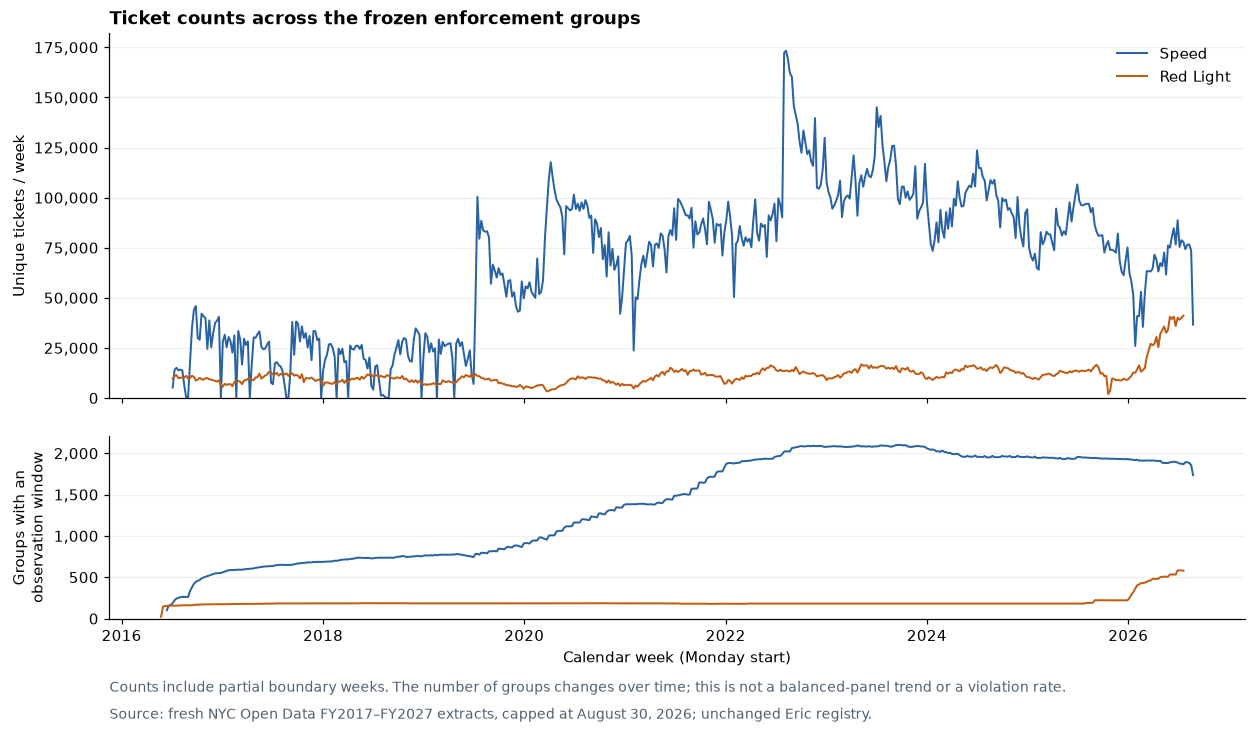

In [4]:
plot_overview(summary, weekly, OUT / 'figures')

### 4. Individual group histories

Examples are deterministic: the lowest, median-ranked, and highest positive ticket totals within each type, with camera ID breaking ties. The browser includes all groups, including empty histories.

In [5]:
examples = select_examples(summary)
display(examples[['camera_id','search_query','camera_type','inferred_activation_date','last_actual_ticket_date','analysis_ticket_count','quality_flags']])

,camera_id,search_query,camera_type,inferred_activation_date,last_actual_ticket_date,analysis_ticket_count,quality_flags
0,cam_14eecd58cbf60a0a,"BATTERY ST WEST ST, NEW YORK, NY",Red Light,2018-01-15,2018-01-17,1,NaN
1,cam_eb4d0c95c0b24034,"W 145TH ST AND LENO X AVE, NEW YORK, NY",Red Light,2026-01-26,2026-07-26,1617,NaN
2,cam_49bf74537c19e71b,"ASTORIA BLVD S AND 77TH ST, NEW YORK, NY",Red Light,2016-06-06,2026-07-26,133788,NaN
3,cam_0268e29606216b5b,"E.170 ST. WALTN A V- EDWRD L GRNT HWY, NEW YOR...",Speed,2022-10-24,2022-10-25,1,NaN
4,cam_d048eb7b45f03539,"GLEN ST. EDWARD C URRY AVE - LOIS LANE, NEW YO...",Speed,2023-05-15,2023-08-14,1037,NaN
5,cam_3fba8be7f3891741,"N CONDUIT AVE AND 8 8TH ST, NEW YORK, NY",Speed,2023-07-03,2026-08-27,447561,NaN


### Example 1

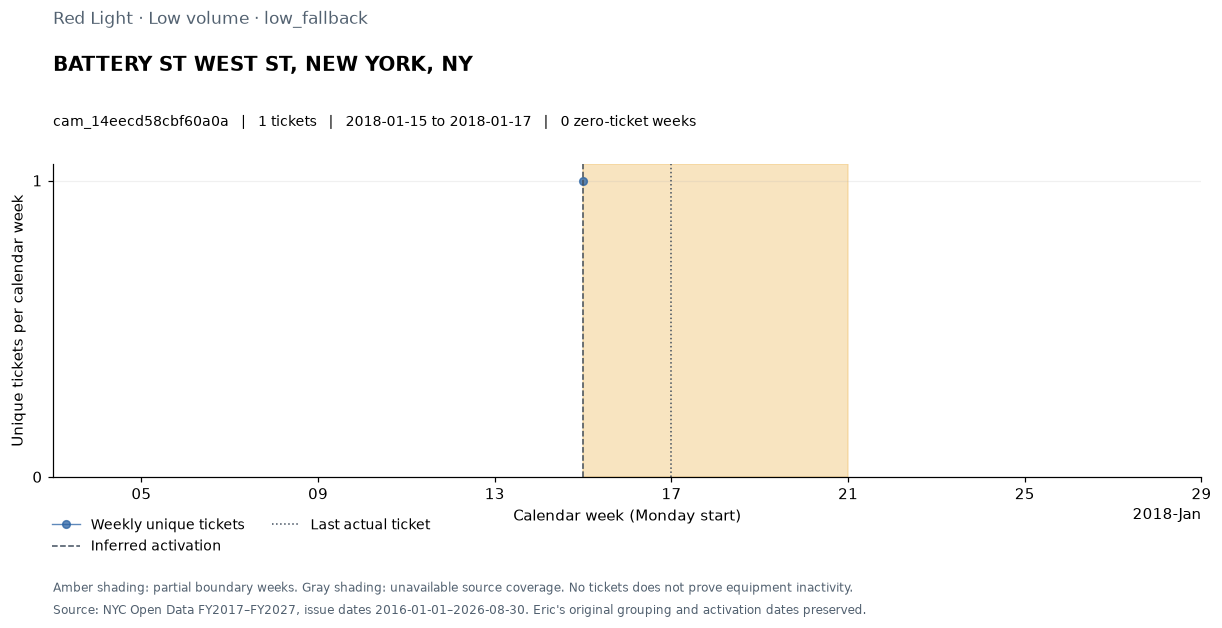

In [6]:
row = examples.iloc[0]
plot_group(row, weekly[weekly.camera_id.eq(row.camera_id)], OUT / 'figures')

### Example 2

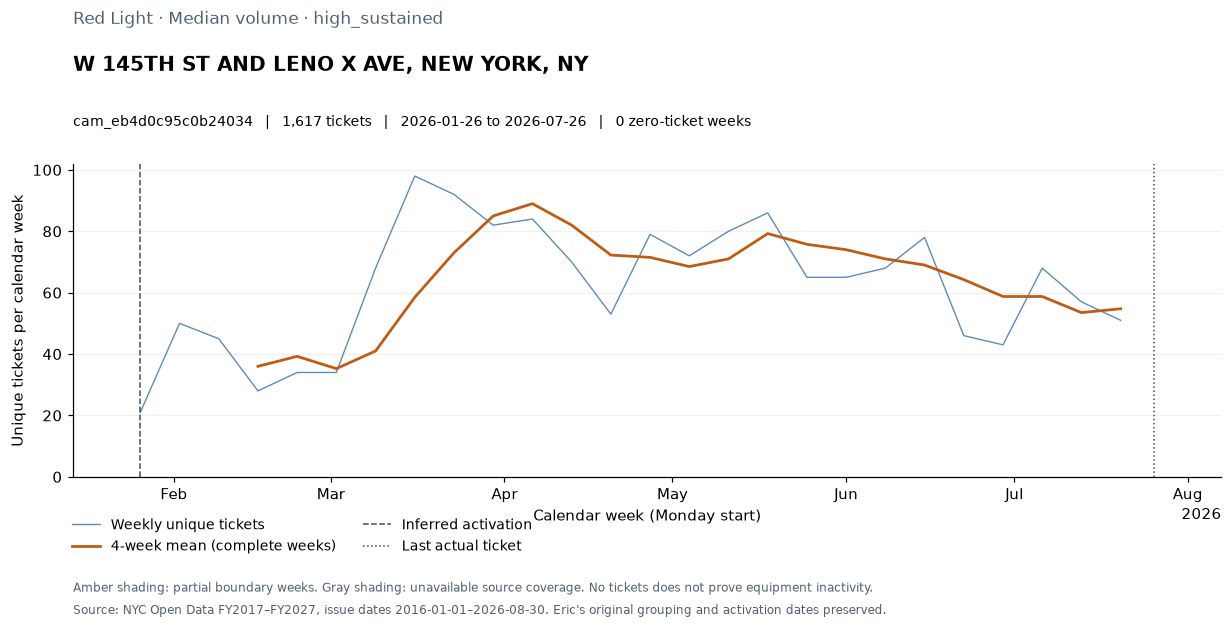

In [7]:
row = examples.iloc[1]
plot_group(row, weekly[weekly.camera_id.eq(row.camera_id)], OUT / 'figures')

### Example 3

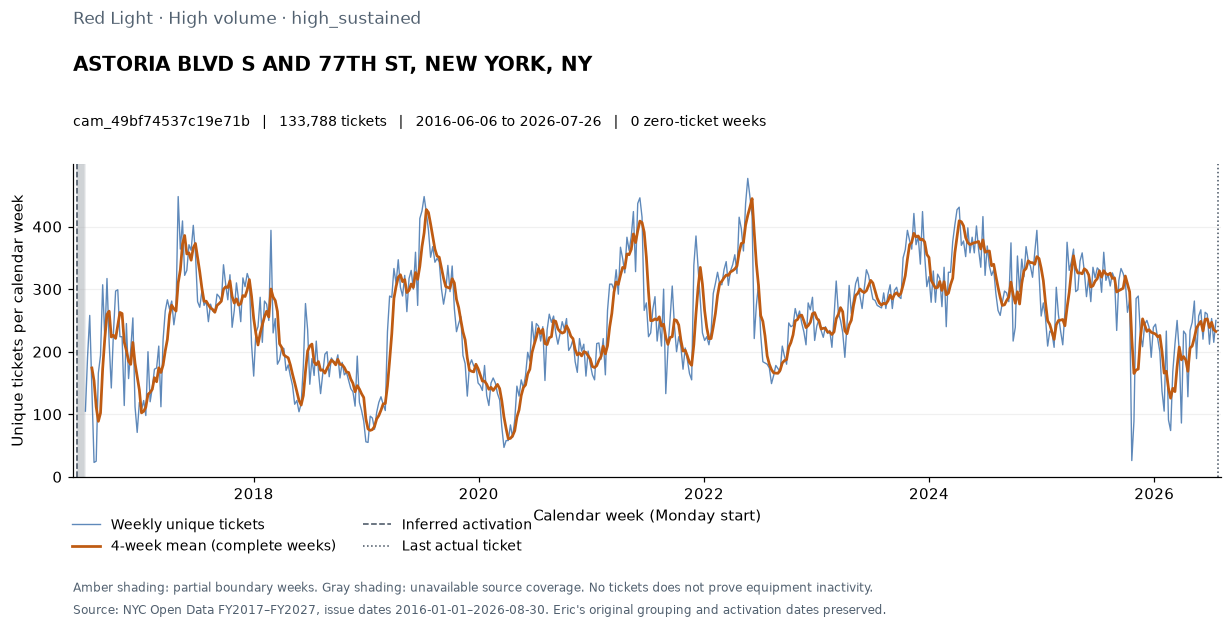

In [8]:
row = examples.iloc[2]
plot_group(row, weekly[weekly.camera_id.eq(row.camera_id)], OUT / 'figures')

### Example 4

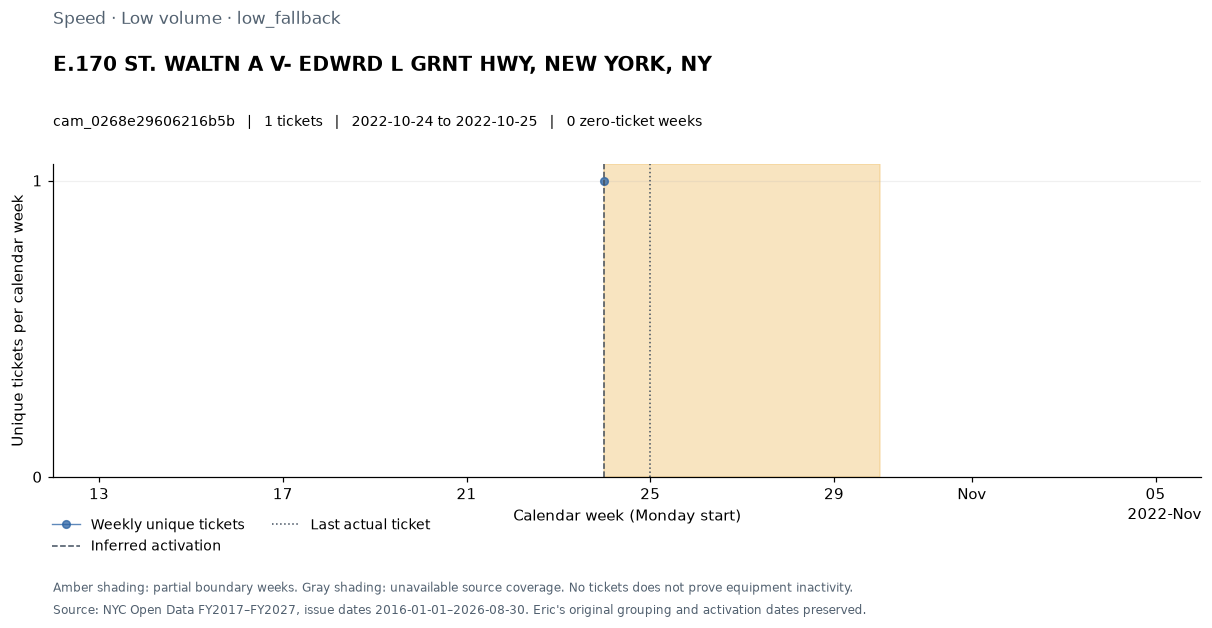

In [9]:
row = examples.iloc[3]
plot_group(row, weekly[weekly.camera_id.eq(row.camera_id)], OUT / 'figures')

### Example 5

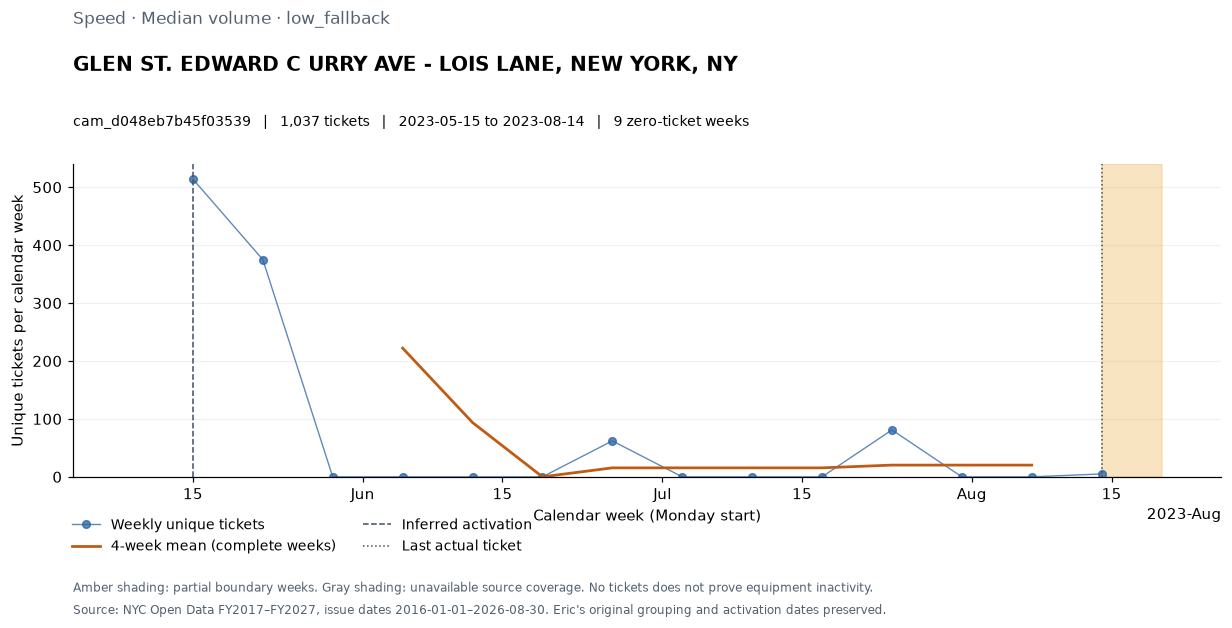

In [10]:
row = examples.iloc[4]
plot_group(row, weekly[weekly.camera_id.eq(row.camera_id)], OUT / 'figures')

### Example 6

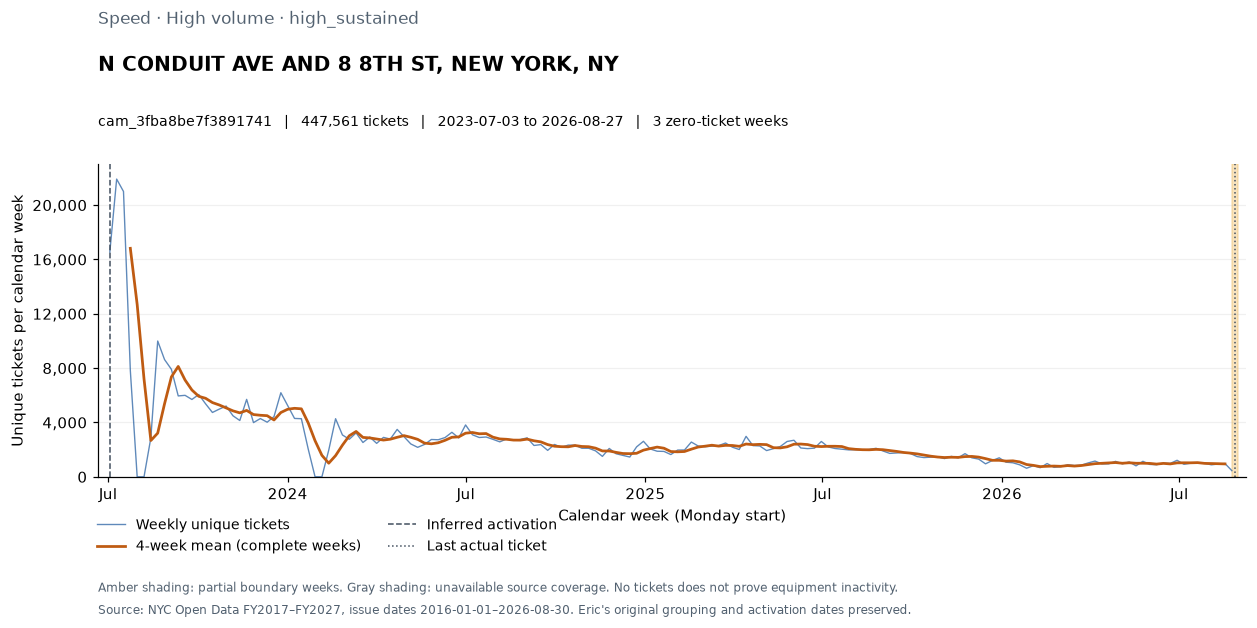

In [11]:
row = examples.iloc[5]
plot_group(row, weekly[weekly.camera_id.eq(row.camera_id)], OUT / 'figures')

### 5. First versus last 13 complete weeks

Each row compares its own eligible windows. Seasonal differences, policy changes, changing traffic, and uncertain operation can affect these descriptive differences.

In [12]:
eligible = summary[summary.first_13w_mean.notna()].copy()
display(eligible.groupby('camera_type').agg(Eligible_groups=('camera_id','size'),Median_absolute_change=('absolute_change','median'),Median_percentage_change=('percentage_change','median')).round(2))
direction = eligible.assign(Change=eligible.absolute_change.map(lambda x: 'Higher final mean' if x > 0 else 'Lower final mean' if x < 0 else 'Unchanged mean'))
display(pd.crosstab(direction.camera_type, direction.Change))
display(eligible[['camera_id','search_query','comparison_start','comparison_end','first_13w_mean','last_13w_mean','absolute_change','percentage_change']].head(10).round(2))

,Eligible_groups,Median_absolute_change,Median_percentage_change
camera_type,,,
Red Light,378,13.65,49.53
Speed,3442,-10.50,-73.74


Change,Higher final mean,Lower final mean,Unchanged mean
camera_type,,,
Red Light,256,122,0
Speed,289,3105,48


,camera_id,search_query,comparison_start,comparison_end,first_13w_mean,last_13w_mean,absolute_change,percentage_change
0,cam_252f148e5cf5b50a,"1 AV E 7ST. - E 1 4 ST, NEW YORK, NY",2016-07-04,2022-07-17,0.85,1.54,0.69,81.82
1,cam_01020d7dded2808f,"1 AV E102 ST. - E 110 ST, NEW YORK, NY",2016-07-04,2026-03-15,4.38,0.00,-4.38,-100.00
2,cam_6c1d3bfa071503e0,"1 AV E117 ST. - E 124 ST, NEW YORK, NY",2016-09-12,2025-10-12,6.00,0.85,-5.15,-85.90
3,cam_e7978d32ac633246,"1 AV E92 ST. - E1 00 ST, NEW YORK, NY",2017-01-09,2026-04-05,11.77,0.23,-11.54,-98.04
4,cam_834087bed0f73bb8,"1 AV. E 3 ST - E 4 ST, NEW YORK, NY",2021-11-15,2023-12-24,1.38,0.00,-1.38,-100.00
5,cam_e423fae7ef046075,"1 AVE. E33 ST- E3 8 ST, NEW YORK, NY",2017-06-12,2019-10-27,0.46,0.00,-0.46,-100.00
6,cam_8a363e6c4c8569e0,"10 AV DYCKMAN ST - W203 ST, NEW YORK, NY",2016-09-12,2019-01-13,23.62,12.46,-11.15,-47.23
7,cam_1701b2305e9bbdfe,"10 AV W203 ST - D YCKMAN ST, NEW YORK, NY",2016-10-10,2018-12-16,28.00,1.62,-26.38,-94.23
9,cam_7b32f7286b033bdf,"10 AVE. W22 ST- W 29 ST, NEW YORK, NY",2017-01-30,2020-03-15,0.08,0.92,0.85,1100.00
10,cam_16705e99e94d4ba9,"10 ST AND CANNON BL VD, NEW YORK, NY",2020-02-24,2026-08-16,99.85,3.62,-96.23,-96.38


### 6. Compare with Eric's saved observations

The comparison uses all matched dates within the extraction window, including tickets preceding inferred activation. It must not be compared directly with post-activation-only counts. Old last-ticket values are week starts; new values are actual ticket dates.

In [13]:
display(pd.DataFrame([{'Groups with different all-period totals':int(summary.count_difference_from_eric.ne(0).sum()),'Groups with changed last observed week':int(summary.last_week_changed.sum()),'Groups with quality flags':int(summary.quality_flags.fillna('').ne('').sum())}]))
display(summary[['camera_id','total_tickets_issued','new_total_all_dates','count_difference_from_eric','last_ticket_date','last_actual_ticket_date']].head(10))

,Groups with different all-period totals,Groups with changed last observed week,Groups with quality flags
0,2233,0,373


,camera_id,total_tickets_issued,new_total_all_dates,count_difference_from_eric,last_ticket_date,last_actual_ticket_date
0,cam_252f148e5cf5b50a,167,167,0,2022-07-18,2022-07-19
1,cam_01020d7dded2808f,607,594,-13,2026-03-16,2026-03-18
2,cam_6c1d3bfa071503e0,536,528,-8,2025-10-13,2025-10-16
3,cam_e7978d32ac633246,799,795,-4,2026-04-06,2026-04-09
4,cam_834087bed0f73bb8,26,26,0,2023-12-25,2023-12-28
5,cam_e423fae7ef046075,22,22,0,2019-10-28,2019-10-31
6,cam_8a363e6c4c8569e0,2067,2067,0,2019-01-14,2019-01-16
7,cam_1701b2305e9bbdfe,1088,1088,0,2018-12-17,2018-12-17
8,cam_7337c0592737b625,19,19,0,2020-03-02,2020-03-03
9,cam_7b32f7286b033bdf,73,73,0,2020-03-16,2020-03-18


## Takeaways

Use the interactive directory to inspect the complete population before interpreting individual examples. A declining curve alone does not identify its cause. Eric's original activation estimates are retained even where low confidence or inherited normalization limitations apply. Any gap after the final observed ticket remains an observation limitation, not a confirmed shutdown.

### Reproducibility

From the repository root, run `uv sync --locked`, then the download, preprocessing, validation, and build commands in this folder's README. Reading saved outputs does not require a download. Raw caches are intentionally local.

In [14]:
checks = pd.read_csv(OUT / 'validation_checks.csv')
assert checks.passed.all()
assert len(summary) == 4610
assert not weekly.duplicated(['camera_id','week_start']).any()
print(f'{len(checks):,} reconciliation checks passed; original activation dates preserved.')

41,500 reconciliation checks passed; original activation dates preserved.
